# 실험 A00: negative 없이 학습 + softmax 로 거절 (논문에 없는 추가)
설계·예측은 `EXPERIMENT_DESIGN.md` 4.1절 (돌리기 전에 적어 둠).

- 학습: `data/train.jsonl` 에서 **positive 2,000개만** (`--only-kind positive`). 나머지 설정은 ours(A50)와 같다 (3 epoch → 375 step)
- 거절: `<nexa_20>` 을 배운 적이 없으므로 **MSP** = 1 − (함수 토큰 20개 중 최대 확률) 이 문턱값 이상이면 거절
- 채점: **우리 test(800, dev)** 와 **공식 210** 두 채점기. 각각 ① greedy 정답 유무 (`src.evaluate score`) ② softmax 확률 저장 (`src.probs`) ③ 정답 + softmax 채점 (`src.softmax_score`)
- 문턱값: dev(우리 test) positive 의 90% 가 거절되지 않게 dev 에서 정하고, 공식 210 에 그대로 쓴다
- 비교: 같은 채점을 기존 ours·공개 모델에도 한다 (점수 `irr` = `<nexa_20>` 확률, `msp` 둘 다)
- MASSIVE·BFCL 은 이 노트북에서 채점하지 않는다 (설계 문서 7절 5단계 규칙)

런타임: **A100 GPU + 고용량 RAM (80GB)**. 🔑 Secrets 에 `HF_TOKEN` (노트북 액세스 켜기)
결과: Drive `MyDrive/octopus_v2/runs/A00/` (모델), `runs/eval/A00/` (우리 test), `runs/eval_official/A00/` (공식 210)

## 준비 (그냥 실행)

In [1]:
# 다른 노트북과 같은 버전 (최신 5.x 는 API 가 바뀌어 에러가 난다)
!pip -q install transformers==4.56.2 accelerate
from huggingface_hub import login
from google.colab import userdata, drive

login(userdata.get("HF_TOKEN"))
drive.mount("/content/drive")

import os
REPO = "/content/octopus_v2_reproduce"
if not os.path.exists(REPO):
    !git clone https://github.com/nahcub/octopus_v2_reproduce.git {REPO}
%cd {REPO}
!git pull
!git log --oneline -1

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
Mounted at /content/drive
Cloning into '/content/octopus_v2_reproduce'...
remote: Enumerating objects: 263, done.
remote: Counting objects: 100% (263/263), done.
remote: Compressing objects: 100% (198/198), done.
remote: Total 263 (delta 144), reused 166 (delta 60), pack-reused 0 (from 0)
Receiving objects: 100% (263/263), 2.20 MiB | 40.28 MiB/s, done.
Resolving deltas: 100% (144/144), done.
/content/octopus_v2_reproduce
Already up to date.
e383e93 (HEAD -> main, origin/main,

In [2]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
import transformers; print("transformers", transformers.__version__)  # 4.56.2 여야 함

DRIVE = "/content/drive/MyDrive/octopus_v2"
RUN_DIR = f"{DRIVE}/runs/A00"                 # 이번에 학습할 모델
DEV_EVAL = f"{DRIVE}/runs/eval"               # 우리 test 결과 (05 노트북과 같은 곳)
OFF_EVAL = f"{DRIVE}/runs/eval_official"      # 공식 210 결과 (06 노트북과 같은 곳)
DEV_TEST = "data/test.jsonl"
OFF_TEST = "data/raw/official/official_test.jsonl"

# 평가할 모델: 이름 -> 폴더 또는 HF 이름. 이름은 결과 폴더 이름
MODELS = {
    "A00": RUN_DIR,
    "ours": f"{DRIVE}/runs/full",       # = A50
    "public": "NexaAIDev/Octopus-v2",
}
# 모델마다 볼 거절 점수. A00 은 <nexa_20> 을 안 배웠으니 msp 만 의미 있다
SCORES = {"A00": ["msp"], "ours": ["irr", "msp"], "public": ["irr", "msp"]}

name, memory.total [MiB]
NVIDIA A100-SXM4-80GB, 81920 MiB
transformers 4.56.2


---
## 1. 학습 데이터 확인
**예측**: positive 몇 개, negative 몇 개가 학습에 들어갈까?
> (여기에 예측)

In [3]:
import json, collections
rows = [json.loads(l) for l in open("data/train.jsonl", encoding="utf-8")]
print("전체", collections.Counter(r["kind"] for r in rows))
pos = [r for r in rows if r["kind"] == "positive"]
print("A00 학습", len(pos), "개 | 함수별 개수", sorted(set(collections.Counter(r["function"] for r in pos).values())))

전체 Counter({'positive': 2000, 'negative': 2000})
A00 학습 2000 개 | 함수별 개수 [100]


## 2. 학습 전 점검 → 짧은 시험 → 본 학습
확인할 것: `[데이터] 2000개`. 메모리 부족이 나면 04 노트북 4-4 의 옵션을 `EXTRA` 에 넣고 README 에 기록

In [4]:
EXTRA = ""   # 예: "--batch-size 4 --grad-accum 4"
!python -m src.train --only-kind positive --check-only {EXTRA}

I0000 00:00:1795314060.777176    1185 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795314060.852828    1185 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795314063.549480    1185 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795314063.550151    1185 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.

In [5]:
!python -m src.train --only-kind positive --max-steps 30 --output-dir /content/runs/try_A00 {EXTRA}

I0000 00:00:1795314120.481693    1615 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795314120.553585    1615 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795314123.141455    1615 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795314123.141997    1615 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.

In [6]:
# 본 학습: 2,000 ÷ 16 = 125 step × 3 = 375 step. 시작·끝 시각을 기록해 둔다 (설계 문서 7절 "학습 1회 시간")
import datetime; print("시작", datetime.datetime.now())
!python -m src.train --only-kind positive --output-dir {RUN_DIR} {EXTRA}
print("끝", datetime.datetime.now())

시작 2026-11-22 02:23:04.897232
I0000 00:00:1795314190.604955    1990 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795314190.679441    1990 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795314193.239225    1990 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795314193.239792    1990 cudart_stub.cc:31] Could not find cuda drivers on your 

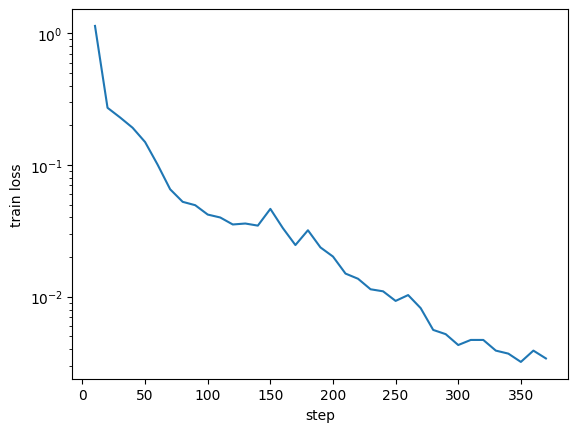

In [7]:
# loss 곡선
import matplotlib.pyplot as plt
logs = [l for l in json.load(open(f"{RUN_DIR}/log_history.json")) if "loss" in l]
plt.plot([l["step"] for l in logs], [l["loss"] for l in logs]); plt.xlabel("step"); plt.ylabel("train loss"); plt.yscale("log"); plt.show()

---
## 3. 우리 test (800, dev) 채점
세션이 끊겼으면 준비 셀 두 개를 실행하고 여기부터. 생성은 이미 있는 줄은 건너뛰고 이어서 한다 (ours·public 은 05 노트북 결과가 있으면 거의 바로 끝남).

**예측**: A00 의 greedy negative 정확도는? MSP 로 거르면 negative 몇 % 를 거절할까?
> (여기에 예측)

In [8]:
# ① greedy 생성 + 정답 유무 채점  ② softmax 확률 저장
for name, path in MODELS.items():
    out = f"{DEV_EVAL}/{name}"
    print(f"===== {name}: {path}")
    !python -m src.evaluate generate --model "{path}" --test-file {DEV_TEST} --out {out}/preds.jsonl
    !python -m src.evaluate score --preds {out}/preds.jsonl --test-file {DEV_TEST}
    !python -m src.probs generate --model "{path}" --test-file {DEV_TEST} --preds {out}/preds.jsonl --out {out}/probs.jsonl

===== A00: /content/drive/MyDrive/octopus_v2/runs/A00
[생성] 800개 중 이미 0개 있음 → 800개 생성 → /content/drive/MyDrive/octopus_v2/runs/eval/A00/preds.jsonl
I0000 00:00:1795314485.692402    3300 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795314485.806242    3300 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795314489.107832    3300 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF

In [9]:
# ③ 정답 + softmax 채점. 문턱값은 각 모델 자기 dev 에서 정한다 (여기서는 test = dev 라 낙관적인 숫자)
for name in MODELS:
    for sc in SCORES[name]:
        out = f"{DEV_EVAL}/{name}"
        print(f"\n#################### {name} | 점수 {sc}")
        !python -m src.softmax_score --test-file {DEV_TEST} --scored {out}/scored.jsonl --probs {out}/probs.jsonl --dev-probs {out}/probs.jsonl --score {sc}


#################### A00 | 점수 msp
test data/test.jsonl (positive 400, negative 400) | 점수 msp | 문턱값 t = 0.3644 (dev positive recall 90% (⚠️ test = dev: 같은 셋에서 정하고 적용, 낙관적))
함수 토큰을 고르지 않은 출력: 24개 (점수 0 으로 둠)

                              greedy        문턱값 적용
전체 정확도                        44.88%        85.50%
  positive                    89.75%        80.25%
  negative                     0.00%        90.75%
AUROC (문턱값 무관)                 0.931

[문턱값 적용 결과 종류] {'args:rule_violation': 1, 'args:valid_but_different': 34, 'correct': 684, 'false_call': 37, 'format:unparsable': 4, 'threshold_refused': 40}

[softmax 확률 중앙값]  p_top = 함수 20개 중 최대 확률, p_irr = <nexa_20> 확률, score = 거절 점수(msp)
                                개수     p_top     p_irr     score
positive greedy 정답             359    0.7403    0.0000    0.2597
positive greedy 오답              41    0.7120    0.0000    0.2880
negative greedy 정답(거절)           0         -         -         -
negative greedy 오답(호출)         400    0.2233    0

---
## 4. 공식 210 채점
문턱값은 3절의 dev(우리 test) probs 에서 정한 값을 그대로 쓴다.

**예측**: 공식 210 에서 A00(MSP) 와 ours(`<nexa_20>`) 의 차이는 dev 보다 클까 작을까?
> (여기에 예측)

In [10]:
!python -m src.official_bench convert
for name, path in MODELS.items():
    out = f"{OFF_EVAL}/{name}"
    print(f"===== {name}: {path}")
    !python -m src.evaluate generate --model "{path}" --test-file {OFF_TEST} --out {out}/preds.jsonl
    !python -m src.evaluate score --preds {out}/preds.jsonl --test-file {OFF_TEST}
    !python -m src.probs generate --model "{path}" --test-file {OFF_TEST} --preds {out}/preds.jsonl --out {out}/probs.jsonl

[다운로드] https://huggingface.co/NexaAIDev/Octopus-v2/resolve/main/android_benchmark.xlsx
[저장] data/raw/official/official_test.jsonl: 210개 {'positive': 200, 'negative': 10}, seen_in_train 0개, 질의 중복 6개
[우리 RULES 를 어기는 공식 정답] 1개
   192 Make a phone call to '+12345678900,555' where '555' is the e ["phone_number: bad value '+12345678900,555'"]
===== A00: /content/drive/MyDrive/octopus_v2/runs/A00
[생성] 210개 중 이미 0개 있음 → 210개 생성 → /content/drive/MyDrive/octopus_v2/runs/eval_official/A00/preds.jsonl
I0000 00:00:1795315108.303411    6440 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795315108.391072    6440 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX

In [11]:
for name in MODELS:
    for sc in SCORES[name]:
        print(f"\n#################### {name} | 점수 {sc}")
        !python -m src.softmax_score --test-file {OFF_TEST} --scored {OFF_EVAL}/{name}/scored.jsonl --probs {OFF_EVAL}/{name}/probs.jsonl --dev-probs {DEV_EVAL}/{name}/probs.jsonl --score {sc}


#################### A00 | 점수 msp
test data/raw/official/official_test.jsonl (positive 200, negative 10) | 점수 msp | 문턱값 t = 0.3644 (dev positive recall 90%)
함수 토큰을 고르지 않은 출력: 0개 (점수 0 으로 둠)

                              greedy        문턱값 적용
전체 정확도                        71.90%        61.90%
  positive                    75.50%        60.00%
  negative                     0.00%       100.00%
AUROC (문턱값 무관)                 0.998

[문턱값 적용 결과 종류] {'args:rule_violation': 1, 'args:valid_but_different': 35, 'correct': 130, 'format:unparsable': 2, 'threshold_refused': 42}

[softmax 확률 중앙값]  p_top = 함수 20개 중 최대 확률, p_irr = <nexa_20> 확률, score = 거절 점수(msp)
                                개수     p_top     p_irr     score
positive greedy 정답             151    0.7285    0.0000    0.2715
positive greedy 오답              49    0.7123    0.0000    0.2877
negative greedy 정답(거절)           0         -         -         -
negative greedy 오답(호출)          10    0.1705    0.0000    0.8295

[거절 점수 분포] 구간별 개수

---
## 5. 나란히 보기
- `greedy`: 기본 생성 그대로 채점 (정답 유무만)
- `t 적용`: 거절 점수가 dev 문턱값 이상이면 거절로 바꿔 채점
- `AUROC`: 거절 점수로 positive / negative 를 가르는 능력 (문턱값 무관)

In [12]:
def load(d, name, sc):
    return json.load(open(f"{d}/{name}/softmax_{sc}_summary.json", encoding="utf-8"))

for title, d in (("우리 test (dev, 문턱값을 같은 셋에서 정함)", DEV_EVAL), ("공식 210 (dev 문턱값 적용)", OFF_EVAL)):
    print(f"\n== {title}")
    print(f"{'모델:점수':<14}{'AUROC':>8}{'greedy 전체':>12}{'pos':>8}{'neg':>8}{'t 적용 전체':>12}{'pos':>8}{'neg':>8}{'t':>10}")
    for name in MODELS:
        for sc in SCORES[name]:
            s = load(d, name, sc); g, ta = s["greedy"], s["threshold_applied"]
            print(f"{name + ':' + sc:<14}{s['auroc']:>8.3f}{g['acc']:>12.1%}{g['acc_positive']:>8.1%}{g['acc_negative']:>8.1%}"
                  f"{ta['acc']:>12.1%}{ta['acc_positive']:>8.1%}{ta['acc_negative']:>8.1%}{s['threshold']:>10.3g}")


== 우리 test (dev, 문턱값을 같은 셋에서 정함)
모델:점수            AUROC   greedy 전체     pos     neg     t 적용 전체     pos     neg         t
A00:msp          0.931       44.9%   89.8%    0.0%       85.5%   80.2%   90.8%     0.364
ours:irr         1.000       94.2%   88.8%   99.8%       90.1%   80.2%  100.0%   0.00462
ours:msp         1.000       94.2%   88.8%   99.8%       90.0%   80.0%  100.0%    0.0687
public:irr       0.944       48.0%   56.8%   39.2%       70.1%   54.2%   86.0%   0.00241
public:msp       0.951       48.0%   56.8%   39.2%       70.8%   53.8%   87.8%    0.0433

== 공식 210 (dev 문턱값 적용)
모델:점수            AUROC   greedy 전체     pos     neg     t 적용 전체     pos     neg         t
A00:msp          0.998       71.9%   75.5%    0.0%       61.9%   60.0%  100.0%     0.364
ours:irr         0.994       69.0%   67.5%  100.0%       53.3%   51.0%  100.0%   0.00462
ours:msp         0.993       69.0%   67.5%  100.0%       53.8%   51.5%  100.0%    0.0687
public:irr       1.000       92.9%   92.5%  100.0%  

In [13]:
# 짝지은 bootstrap 으로 차이와 95% 구간 (기준: 첫 번째 = ours 의 <nexa_20>)
args = " ".join(f"--model {n}:{sc} {DEV_EVAL}/{n}/probs.jsonl {DEV_EVAL}/{n}/probs.jsonl" for n in ["ours", "A00", "public"] for sc in SCORES[n])
!python -m src.refusal_metrics --test {DEV_TEST} {args} | tee {DEV_EVAL}/A00_refusal_metrics.txt
args = " ".join(f"--model {n}:{sc} {OFF_EVAL}/{n}/probs.jsonl {DEV_EVAL}/{n}/probs.jsonl" for n in ["ours", "A00", "public"] for sc in SCORES[n])
!python -m src.refusal_metrics --test {OFF_TEST} --dev-test {DEV_TEST} {args} | tee {OFF_EVAL}/A00_refusal_metrics.txt

test: data/test.jsonl (positive 400, negative 400), recall 기준 90%, bootstrap 1000회

== ours:irr  (dev 문턱값 t = 0.004615)
  auroc                              1.000  95% [1.000, 1.000]
  refuse@r                           1.000  95% [1.000, 1.000]
  pos_recall                         0.900  95% [0.870, 0.927]

== ours:msp  (dev 문턱값 t = 0.06874)
  auroc                              1.000  95% [1.000, 1.000]
  refuse@r                           1.000  95% [1.000, 1.000]
  pos_recall                         0.900  95% [0.870, 0.930]

== A00:msp  (dev 문턱값 t = 0.3644)
  auroc                              0.931  95% [0.907, 0.954]
  refuse@r                           0.907  95% [0.877, 0.935]
  pos_recall                         0.900  95% [0.870, 0.930]

== public:irr  (dev 문턱값 t = 0.002413)
  auroc                              0.944  95% [0.924, 0.960]
  refuse@r                           0.860  95% [0.825, 0.895]
  pos_recall                         0.900  95% [0.870, 0.927]

== public:msp 

---
## 끝나면
결과는 Drive `runs/eval/A00/`, `runs/eval_official/A00/` 의 `softmax_msp_scored.jsonl` (문항별 확률·판정) 과 `softmax_msp_summary.json`.
랩탑에서 Claude 에게 "A00 결과 분석해줘" 라고 하면 Drive 에서 받아 설계 문서 4.1절 예측과 비교한다.